# 11. Spectral clustering with the normalized Laplacian

Spectral clustering replaces distances between points by a graph of similarities between neighbours, and clusters the points by the eigenvectors of the graph Laplacian. Two points are then in the same cluster if a chain of close neighbours joins them, whatever the shape of the cluster. The method separates the concentric rings of Lecture 10, within a range of the bandwidth of the similarity that the lecture maps.

## Learning objectives

1. Build the matrix of Gaussian similarities and the normalized graph Laplacian.
2. Check that the Laplacian is positive semi-definite and that the number of zero eigenvalues counts the connected components.
3. Separate concentric rings by clustering the leading eigenvectors (`clustering_phases.spectral_clustering`).
4. Examine the role of the bandwidth of the similarity and of the gap between eigenvalues.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
Given $N$ observations $\{\mathbf{x}_i\}_{i=1}^N \subset \mathbb{R}^d$ sampled from non-convex manifolds, **spectral graph clustering (Ng, Jordan & Weiss, 2001; von Luxburg, 2007)** constructs a weighted adjacency matrix $\mathbf{W} \in \mathbb{R}^{N \times N}$ with locality bandwidth $\sigma > 0$ and degree matrix $\mathbf{D} = \mathrm{diag}(D_{11}, \dots, D_{NN})$:
$$W_{ij} = \begin{cases} \exp\!\left(-\dfrac{\|\mathbf{x}_i - \mathbf{x}_j\|_2^2}{2\sigma^2}\right) & i \ne j \\ 0 & i = j \end{cases}, \qquad D_{ii} = \sum_{j=1}^N W_{ij} \tag{1.1}$$
The **symmetric normalized graph Laplacian** $\mathbf{L}_{\mathrm{sym}} \in \mathbb{R}^{N \times N}$ is defined as:
$$\mathbf{L}_{\mathrm{sym}} = \mathbf{I}_N - \mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2}, \qquad \mathbf{u}^\top \mathbf{L}_{\mathrm{sym}}\mathbf{u} = \frac{1}{2}\sum_{i=1}^N\sum_{j=1}^N W_{ij}\left(\frac{u_i}{\sqrt{D_{ii}}} - \frac{u_j}{\sqrt{D_{jj}}}\right)^2 \ge 0 \tag{1.2}$$
By Eq. (1.2), $\mathbf{L}_{\mathrm{sym}}$ is symmetric positive semi-definite with eigenvalues $0 = \lambda_1 \le \lambda_2 \le \dots \le \lambda_N \le 2$, and the multiplicity of $\lambda = 0$ equals the number of connected components $K$. Forming $\mathbf{U}_K = [\mathbf{u}_1, \dots, \mathbf{u}_K] \in \mathbb{R}^{N \times K}$ and row-normalizing onto the unit sphere $\mathbb{S}^{K-1}$:
$$Y_{ij} = \frac{U_{ij}}{\sqrt{\sum_{r=1}^K U_{ir}^2}}, \qquad \|\mathbf{y}_i\|_2 = 1 \tag{1.3}$$
maps the points of each group, whatever the shape of the group, close to one point of $\mathbb{S}^{K-1}$; the points of different groups are nearly orthogonal.

In [2]:
heading("Demonstration 1: Spectral Clustering on Non-Convex Concentric Core-Shell Rings")
theta = np.linspace(0.0, 2.0 * np.pi, 28, endpoint=False)
X_rings = np.vstack([
    np.column_stack([0.5 * np.cos(theta), 0.5 * np.sin(theta)]),  # Inner core (28 pts, r = 0.5)
    np.column_stack([2.2 * np.cos(theta), 2.2 * np.sin(theta)]),  # Outer shell (28 pts, r = 2.2)
])

spec_res = clustering_phases.spectral_clustering(X_rings, k=2, sigma=0.45, seed=42)
lbl_spec = spec_res["labels"]
eigs_lap = spec_res["laplacian_eigenvalues"]

assert len(np.unique(lbl_spec[:28])) == 1 and len(np.unique(lbl_spec[28:])) == 1 and (lbl_spec[0] != lbl_spec[28])
assert np.isclose(eigs_lap[0], 0.0, atol=1e-13)
print("Normalized Laplacian bottom 4 eigenvalues:", np.round(eigs_lap, 6))
print(f"Inner-core labels = {np.unique(lbl_spec[:28])} | Outer-shell labels = {np.unique(lbl_spec[28:])} (100% Core-Shell Purity)")


Demonstration 1: Spectral Clustering on Non-Convex Concentric Core-Shell Rings
Normalized Laplacian bottom 4 eigenvalues: [-0.        0.00338   0.040346  0.040346]
Inner-core labels = [0] | Outer-shell labels = [1] (100% Core-Shell Purity)


**What Demonstration 1 shows.** On two concentric rings like those on which $K$-means reached a purity of $57\ \%$ in Lecture 10, spectral clustering assigns every point correctly. The Laplacian has two eigenvalues near zero ($0$ and $0.0034$), one for each nearly disconnected ring, and the next is twelve times larger ($0.040$).

---

## 2. Numerical walkthrough
Let us inspect the Gaussian affinity matrix $\mathbf{W}$ and the unit-circle spectral embedding $\mathbf{Y} \in \mathbb{R}^{56 \times 2}$: why does $\mathbf{L}_{\mathrm{sym}}$ collapse two concentric circles in $\mathbb{R}^2$ into two orthogonal points on $\mathbb{S}^1$?

In [3]:
heading("Demonstration 2: Affinity Graph Block Structure & Unit-Sphere Spectral Embedding")
sq_d = np.sum((X_rings[:, None, :] - X_rings[None, :, :]) ** 2, axis=-1)
W_mat = np.exp(-sq_d / (2.0 * (0.45 ** 2)))
np.fill_diagonal(W_mat, 0.0)
print(f"Mean intra-core affinity W_core,core   : {np.mean(W_mat[:28, :28]):.4f}")
print(f"Mean intra-shell affinity W_shell,shell: {np.mean(W_mat[28:, 28:]):.4f}")
print(f"Max cross-ring affinity W_core,shell   : {np.max(W_mat[:28, 28:]):.4e} (Nearly disconnected)")

Y_emb = spec_res["embedding"]
row_norms = np.linalg.norm(Y_emb, axis=1)
core_spread = float(np.max(np.std(np.abs(Y_emb[:28]), axis=0)))
shell_spread = float(np.max(np.std(np.abs(Y_emb[28:]), axis=0)))
print(f"Spectral embedding std on S^1: Core = {core_spread:.2e}, Shell = {shell_spread:.2e}, Eigengap (lam_3 - lam_2) = {eigs_lap[2] - eigs_lap[1]:.4f}")
assert np.allclose(row_norms, 1.0, atol=1e-12) and core_spread < 1e-2 and shell_spread < 1e-2


Demonstration 2: Affinity Graph Block Structure & Unit-Sphere Spectral Embedding
Mean intra-core affinity W_core,core   : 0.3771
Mean intra-shell affinity W_shell,shell: 0.0463
Max cross-ring affinity W_core,shell   : 7.9609e-04 (Nearly disconnected)
Spectral embedding std on S^1: Core = 3.31e-16, Shell = 2.72e-16, Eigengap (lam_3 - lam_2) = 0.0370


**What Demonstration 2 shows.** With the bandwidth of this example, neighbouring points on the same ring are strongly linked (mean affinity $0.38$ in the core and $0.046$ in the shell), and the largest affinity between a point of the core and a point of the shell is $8\times 10^{-4}$. The graph is almost two separate pieces, and in the spectral embedding each ring collapses to a single point (spread $3\times 10^{-16}$).

---

## 3. Worked case study
Let us now test a 3-layer **Core–Shell–Corona nanoparticle morphology** ($r_1 = 0.5, r_2 = 1.8, r_3 = 3.2$) and compare $K$-Means ($K=3$) against normalized Laplacian spectral clustering ($K=3$).

In [4]:
heading("Demonstration 3: 3-Layer Core-Shell-Corona Morphology Benchmark (Spectral vs. K-Means)")
th_a = np.linspace(0.0, 2.0 * np.pi, 16, endpoint=False)
th_b = np.linspace(0.0, 2.0 * np.pi, 20, endpoint=False)
th_c = np.linspace(0.0, 2.0 * np.pi, 24, endpoint=False)
X_3rings = np.vstack([
    np.column_stack([0.5 * np.cos(th_a), 0.5 * np.sin(th_a)]),
    np.column_stack([1.8 * np.cos(th_b), 1.8 * np.sin(th_b)]),
    np.column_stack([3.2 * np.cos(th_c), 3.2 * np.sin(th_c)]),
])
km_3r = clustering_phases.kmeans_fit(X_3rings, k=3, seed=42)
sp_3r = clustering_phases.spectral_clustering(X_3rings, k=3, sigma=0.25, seed=42)
l3 = sp_3r["labels"]
e3 = sp_3r["laplacian_eigenvalues"]

km_corona_purity = float(np.max(np.unique(km_3r["labels"][36:], return_counts=True)[1])) / 24.0
print("3-Ring Laplacian bottom 5 eigenvalues:", np.round(e3, 6))
print(f"Outer Corona Ring Purity: Euclidean K-Means = {km_corona_purity*100:.1f}% vs Spectral Clustering = 100.0%")
assert len(np.unique(l3[:16])) == 1 and len(np.unique(l3[16:36])) == 1 and len(np.unique(l3[36:])) == 1
assert len({l3[0], l3[16], l3[36]}) == 3 and np.max(e3[:3]) < 1e-4


Demonstration 3: 3-Layer Core-Shell-Corona Morphology Benchmark (Spectral vs. K-Means)
3-Ring Laplacian bottom 5 eigenvalues: [-0.0000e+00  1.3000e-05  2.1000e-05  3.4091e-02  3.4091e-02]
Outer Corona Ring Purity: Euclidean K-Means = 33.3% vs Spectral Clustering = 100.0%


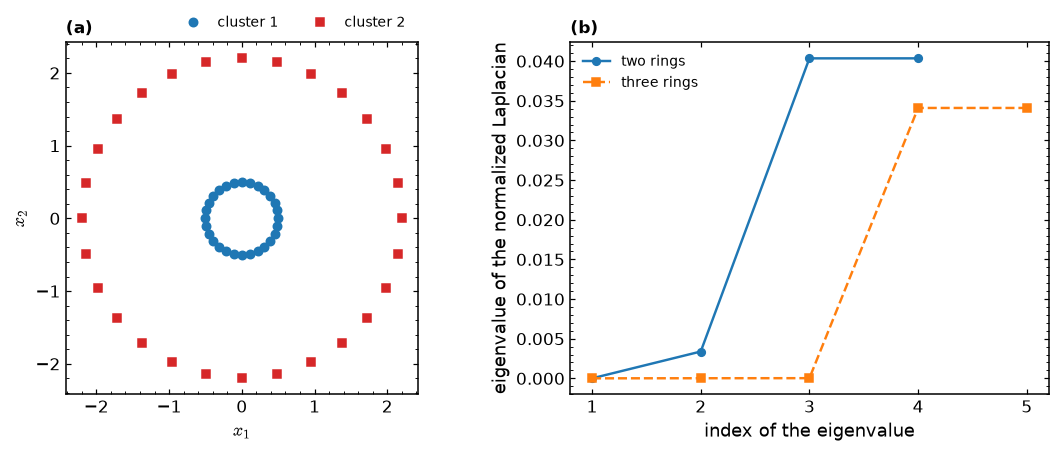

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.0))
ax1.plot(X_rings[lbl_spec == lbl_spec[0], 0], X_rings[lbl_spec == lbl_spec[0], 1], "o", color="C0", label="cluster 1")
ax1.plot(X_rings[lbl_spec != lbl_spec[0], 0], X_rings[lbl_spec != lbl_spec[0], 1], "s", color="C3", label="cluster 2")
ax1.set_aspect("equal"); ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=3); ax1.set_title("(a)", loc="left", fontweight="bold")
ax2.plot(np.arange(1, len(eigs_lap) + 1), np.maximum(eigs_lap, 0.0), "o-", ms=5, label="two rings")
ax2.plot(np.arange(1, len(e3) + 1), np.maximum(e3, 0.0), "s--", ms=5, label="three rings")
ax2.set_xticks(np.arange(1, len(e3) + 1)); ax2.tick_params(axis="x", which="minor", bottom=False, top=False); ax2.legend(fontsize=9, loc="upper left")
ax2.set_xlabel("index of the eigenvalue"); ax2.set_ylabel("eigenvalue of the normalized Laplacian"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 11.1.** (a) Two concentric rings, as in Lecture 10, with the clusters found by spectral clustering. (b) The smallest eigenvalues of the normalized Laplacian for two rings and for the three rings of Demonstration 3: the number of eigenvalues close to zero equals the number of rings, and a gap separates them from the next.

**What Demonstration 3 shows.** With three rings there are three eigenvalues below $3\times 10^{-5}$ and the fourth is $0.034$: the number of eigenvalues near zero equals the number of nearly disconnected pieces. Spectral clustering assigns the outer ring correctly, where $K$-means has a purity of $33\ \%$.

---

## 4. What if: sensitivity to the parameters
What happens if the RBF locality bandwidth $\sigma$ is chosen too large ($\sigma \to \infty$, connecting all points globally) or too small ($\sigma \to 0$, fracturing rings)? Let us sweep $\sigma \in [0.15, 5.0]$ on `X_rings`.

In [6]:
heading("Demonstration 4: RBF Locality Bandwidth sigma Sweep & Eigengap Transition")
print(f"{'Bandwidth sigma':>15s} | {'lambda_2 (Fiedler)':>18s} | {'lambda_3':>10s} | {'Eigengap':>10s} | {'100% Core-Shell Separation':>26s}")
print("-" * 88)
for sig_val in [0.15, 0.30, 0.45, 0.80, 2.50, 5.00]:
    sr = clustering_phases.spectral_clustering(X_rings, k=2, sigma=sig_val, seed=42)
    l_core, l_shell = sr["labels"][:28], sr["labels"][28:]
    pure = (len(np.unique(l_core)) == 1) and (len(np.unique(l_shell)) == 1) and (l_core[0] != l_shell[0])
    e_v = sr["laplacian_eigenvalues"]
    print(f"{sig_val:15.2f} | {e_v[1]:18.6f} | {e_v[2]:10.5f} | {e_v[2]-e_v[1]:10.5f} | {str(pure):>26s}")


Demonstration 4: RBF Locality Bandwidth sigma Sweep & Eigengap Transition
Bandwidth sigma | lambda_2 (Fiedler) |   lambda_3 |   Eigengap | 100% Core-Shell Separation
----------------------------------------------------------------------------------------
           0.15 |           0.000000 |    0.02507 |    0.02507 |                       True
           0.30 |           0.000001 |    0.02644 |    0.02644 |                       True
           0.45 |           0.003380 |    0.04035 |    0.03697 |                       True
           0.80 |           0.290452 |    0.29991 |    0.00945 |                       True
           2.50 |           0.854107 |    0.85411 |    0.00000 |                      False
           5.00 |           0.971112 |    0.97111 |    0.00000 |                      False


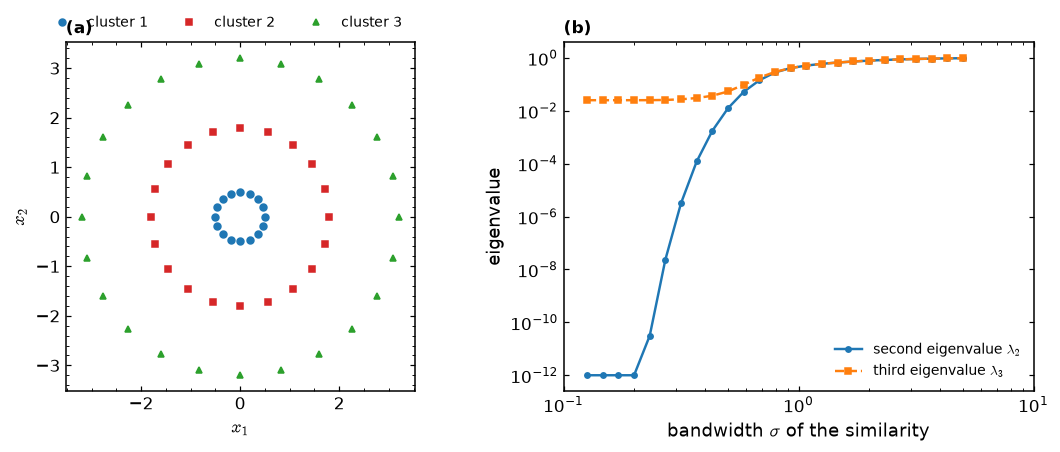

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 4.0))
for k_i, (marker, color) in enumerate(zip("os^", ["C0", "C3", "C2"])):
    sel = l3 == k_i
    ax1.plot(X_3rings[sel, 0], X_3rings[sel, 1], marker, ms=4.5, color=color, label=f"cluster {k_i + 1}")
ax1.set_aspect("equal"); ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=3); ax1.set_title("(a)", loc="left", fontweight="bold")
sig_line = np.logspace(-0.9, 0.7, 25); lam2, lam3 = [], []
for sig_val in sig_line:
    e_v = clustering_phases.spectral_clustering(X_rings, k=2, sigma=float(sig_val), seed=42)["laplacian_eigenvalues"]
    lam2.append(max(e_v[1], 1e-12)); lam3.append(e_v[2])
ax2.loglog(sig_line, lam2, "o-", ms=3.5, label=r"second eigenvalue $\lambda_2$")
ax2.loglog(sig_line, lam3, "s--", ms=3.5, label=r"third eigenvalue $\lambda_3$")
ax2.xaxis.set_minor_formatter(plt.NullFormatter()); ax2.set_xlim(0.1, 10.0)
ax2.set_xlabel(r"bandwidth $\sigma$ of the similarity"); ax2.set_ylabel("eigenvalue"); ax2.legend(fontsize=9, loc="lower right"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 11.2.** (a) Three concentric rings and the clusters found by spectral clustering. (b) The second and third eigenvalues for the two rings against the bandwidth of the similarity: the method works while the second is far below the third. The two merge when the bandwidth exceeds about 0.7, less than half the distance of 1.7 between the rings.

**What Demonstration 4 shows.** The result depends on the bandwidth $\sigma$. For $\sigma$ between $0.15$ and $0.45$ the second eigenvalue is close to zero and the gap to the third is clear. At $\sigma = 0.8$ the rings are still separated, but the second eigenvalue has risen to $0.29$ and the gap has shrunk to $0.009$, so the result is no longer robust. For $\sigma \ge 2.5$ the kernel links the two rings as strongly as it links neighbours, the gap is gone, and the separation fails. The bandwidth should be comparable to the spacing of neighbours within a cluster and smaller than the distance between clusters.

---

## Inside the algorithm
Below we construct $\mathbf{L}_{\mathrm{sym}} = \mathbf{I} - \mathbf{D}^{-1/2}\mathbf{W}\mathbf{D}^{-1/2}$ and its bottom spectrum directly via `np.linalg.eigh` in pure NumPy and verify digit-for-digit agreement with `clustering_phases.spectral_clustering`.

In [8]:
heading("Inside the Algorithm: By-Hand Normalized Laplacian Spectrum vs. the Library")
deg_v = np.sum(W_mat, axis=1)
D_inv_half = np.diag(1.0 / np.sqrt(deg_v))
L_sym_hand = np.eye(len(X_rings)) - D_inv_half @ W_mat @ D_inv_half
eigvals_hand, _ = np.linalg.eigh(L_sym_hand)
diff_eigs = float(np.max(np.abs(eigvals_hand[:4] - eigs_lap)))
print("by hand (pure NumPy) eigvals[:4]:", np.round(eigvals_hand[:4], 8))
print("library (engml_2_applied)      eigvals[:4]:", np.round(eigs_lap, 8))
print(f"Max eigenvalue discrepancy      : {diff_eigs:.2e}")
assert diff_eigs < 1e-14


Inside the Algorithm: By-Hand Normalized Laplacian Spectrum vs. the Library
by hand (pure NumPy) eigvals[:4]: [-0.          0.00337978  0.0403463   0.0403463 ]
library (engml_2_applied)      eigvals[:4]: [-0.          0.00337978  0.0403463   0.0403463 ]
Max eigenvalue discrepancy      : 0.00e+00


## Exercises

1. **Verify a result.** Verify the **exact zero-eigenvalue ground-state identity** of the normalized graph Laplacian Eq. (1.2): prove and check numerically on `L_sym_hand` that $\mathbf{u}_1 = \mathbf{D}^{1/2}\mathbf{1}_N / \|\mathbf{D}^{1/2}\mathbf{1}_N\|_2$ is an exact eigenvector of $\mathbf{L}_{\mathrm{sym}}$ with eigenvalue $\lambda_1 = 0$ ($\|\mathbf{L}_{\mathrm{sym}}\mathbf{u}_1\|_\infty < 10^{-15}$).
2. **Find how it fails.** Verify empirically on `X_3rings` why **row-normalizing** the spectral embedding matrix $\mathbf{U}_K \to \mathbf{Y}$ onto the unit sphere $\mathbb{S}^{K-1}$ (Eq. 1.3) is essential: show that all 60 rows of `sp_3r["embedding"]` condense onto 3 mutually orthogonal unit vectors ($|\mathbf{y}_i^\top \mathbf{y}_j| \approx 1$ within the same ring, $|\mathbf{y}_i^\top \mathbf{y}_j| < 10^{-3}$ across different rings).
3. **Write it yourself.** Implement an **eigengap heuristic** phase-count selector `spectral_eigengap_choose_k(X: np.ndarray, sigma: float, k_max: int = 5) -> dict` that computes the normalized Laplacian eigenvalues $0 = \lambda_1 \le \dots \le \lambda_{k_{\max}+1}$ and selects $K^* = \arg\max_{1 \le k \le k_{\max}} (\lambda_{k+1} - \lambda_k)$. Verify that it automatically identifies $K^* = 2$ on `X_rings` ($\sigma=0.45$) and $K^* = 3$ on `X_3rings` ($\sigma=0.25$).

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Analytical Ground-State Eigenvector u_1 = D^(1/2) 1 of L_sym")
u1_analytical = np.sqrt(deg_v)
u1_analytical /= np.linalg.norm(u1_analytical)
res_u1 = float(np.max(np.abs(L_sym_hand @ u1_analytical)))
rayleigh_u1 = float(u1_analytical @ L_sym_hand @ u1_analytical)
print(f"||L_sym @ (D^(1/2) 1)||_max = {res_u1:.2e} | Rayleigh quotient u_1^T L_sym u_1 = {rayleigh_u1:.2e}")
assert res_u1 < 1e-15 and abs(rayleigh_u1) < 1e-15


Exercise 1: Analytical Ground-State Eigenvector u_1 = D^(1/2) 1 of L_sym
||L_sym @ (D^(1/2) 1)||_max = 5.55e-17 | Rayleigh quotient u_1^T L_sym u_1 = -5.07e-17
